In [2]:
        ################### Deep Neural Networks Regression-Kriging using PyTorch and Random Fourier Features (RFF)
        ################### with The Monte Carlo Inference Function           #############################

In [41]:
# If you receive the message "The kernel ... appears to have died. It will restart automatically."
# OpenMP Runtime Conflict: If you see the crash during imports like Scikit-Learn or PyTorch, set this environment variable at the very top of your notebook:
# Type the following codes

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [42]:
########## 1. Installing and Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim

In [43]:
# 2. Loading the dataset
data = pd.read_csv('E:/VData/SData/Wells4.csv')

In [44]:
seed = 42

In [45]:
data.head()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
0,17.74,15.57,259.0,7.00,39.0,9.0,27.0
1,17.48,15.82,220.0,6.60,17.0,12.0,34.7
2,17.48,15.83,220.0,6.00,925.0,5.0,27.0
3,17.39,15.37,286.0,7.00,3300.0,1.0,29.0
4,17.35,13.80,47.0,7.45,13.0,0.2,26.5


In [46]:
data.describe()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
count,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000
mean,15.499214,13.761732,49.371823,7.047918,49.873158,6.258383,28.451777
std,0.536874,0.508679,19.132128,0.618476,146.064968,15.023649,2.827740
min,13.930000,12.270000,15.400000,4.000000,0.000000,0.000000,10.000000
25%,15.230000,13.440000,38.000000,6.730000,9.000000,1.300000,27.000000
50%,15.480000,13.780000,48.000000,7.000000,18.000000,2.800000,29.000000
75%,15.730000,14.125000,56.000000,7.375000,35.000000,7.000000,30.000000
max,17.740000,15.830000,286.000000,10.800000,3300.000000,278.000000,35.100000


<>:36: SyntaxWarning: invalid escape sequence '\g'
<>:36: SyntaxWarning: invalid escape sequence '\g'
C:\Users\Djimadoumngar\AppData\Local\Temp\ipykernel_14320\988317969.py:36: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('Semi-variance $\gamma(h)$')


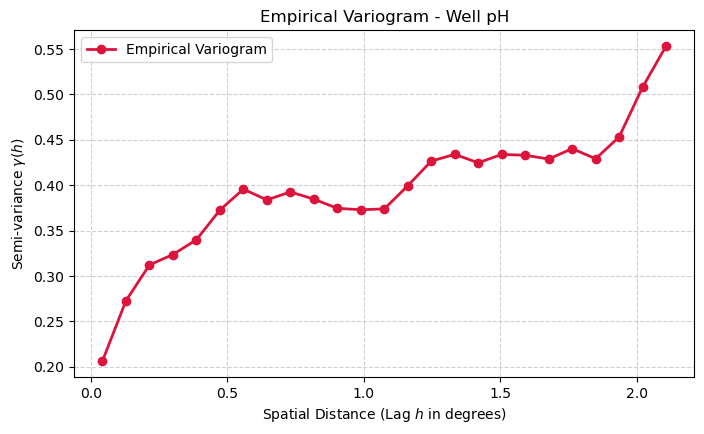

In [47]:
# 3. Empirical Variogram Plotting
# Establishing the spatial correlation by calculating and plotting an Empirical Semi-Variogram before running Deep Kriging.
from scipy.spatial.distance import pdist, squareform
def compute_empirical_variogram(coords, values, n_lags = 20, max_dist = None):
    # Pairwise spatial distances
    dist_matrix = squareform(pdist(coords))
    
    # Pairwise squared differences of values
    val_diff_matrix = 0.5 * (values[:, None] - values[None, :]) ** 2
    
    if max_dist is None:
        max_dist = dist_matrix.max() / 2.0  # Common spatial rule of thumb
        
    bins = np.linspace(0, max_dist, n_lags + 1)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    gamma = []
    
    for i in range(n_lags):
        mask = (dist_matrix >= bins[i]) & (dist_matrix < bins[i+1])
        if np.sum(mask) > 0:
            gamma.append(np.mean(val_diff_matrix[mask]))
        else:
            gamma.append(np.nan)
            
    return bin_centers, np.array(gamma)

# Extracting coordinates and target variable
coords = data[['y_coord', 'x_coord']].values
target = data['pH'].values

lags, gamma = compute_empirical_variogram(coords, target, n_lags = 25)

plt.figure(figsize=(8, 4.5))
plt.plot(lags, gamma, 'o-', color = 'crimson', linewidth = 2, label = 'Empirical Variogram')
plt.xlabel('Spatial Distance (Lag $h$ in degrees)')
plt.ylabel('Semi-variance $\gamma(h)$')
plt.title('Empirical Variogram - Well pH')
plt.grid(True, linestyle = '--', alpha = 0.6)
plt.legend()
plt.show()


In [12]:
############# 4. Implementing Deep Kriging with Spatial Embeddings using Random Fourier Features (RFF)

In [48]:
# a. Creating a RFF class
class RandomFourierEmbedding(nn.Module):
    """
    Random Fourier Feature layer mapping 2D (Lat, Long) coordinates
    into a higher-dimensional spatial embedding space.
    """
    def __init__(self, in_features=2, num_features=128, sigma=1.0):
        super().__init__()
        # Fix random weights representing spatial frequencies
        B = torch.randn(in_features, num_features // 2) * sigma
        self.register_buffer('B', B)

    def forward(self, x):
        # x shape: [batch_size, in_features]
        x_proj = torch.matmul(x, self.B) * 2 * np.pi
        return torch.cat([torch.cos(x_proj), torch.sin(x_proj)], dim=-1)


In [49]:
# b. Creating a Deep kriging class
class DeepKrigingModel(nn.Module):
    """
    Deep Kriging Neural Network Architecture
    """
    def __init__(self, embedding_dim=128, hidden_units=[128, 64, 32]):
        super().__init__()
        self.rff = RandomFourierEmbedding(in_features=2, num_features=embedding_dim, sigma=0.5)
        
        layers = []
        prev_dim = embedding_dim
        for h in hidden_units:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(nn.ReLU())
            layers.append(nn.BatchNorm1d(h))
            prev_dim = h
            
        layers.append(nn.Linear(prev_dim, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        embedded = self.rff(x)
        return self.network(embedded)

In [50]:
# c. Data Normalization
scaler_coords = StandardScaler()
X_scaled = scaler_coords.fit_transform(coords)
y = target.reshape(-1, 1)

In [51]:
# d. Splitting the datset into training and testing dataset
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size = 0.3, random_state = 42)

In [52]:
# e. Converting to PyTorch Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

In [18]:
############### 5. Training the Deep Kriging Model

In [53]:
# a. Training the model
model = DeepKrigingModel(embedding_dim = 256, hidden_units = [128, 64, 32])
criterion = nn.MSELoss()
optimizer = optim.RMSprop(model.parameters(), lr = 0.003, weight_decay = 1e-4)

epochs = 300
train_losses = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    preds = model(X_train_t)
    loss = criterion(preds, y_train_t)
    
    loss.backward()
    optimizer.step()
    
    train_losses.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - Loss (MSE): {loss.item():.2f}")

Epoch [50/300] - Loss (MSE): 1.11
Epoch [100/300] - Loss (MSE): 0.14
Epoch [150/300] - Loss (MSE): 0.12
Epoch [200/300] - Loss (MSE): 0.11
Epoch [250/300] - Loss (MSE): 0.09
Epoch [300/300] - Loss (MSE): 0.07


In [20]:
######## 6. Model Performance Evaluation

In [21]:
# a. Evaluating the Performance of the training model

In [54]:
# Training R2
model.eval()
with torch.no_grad():
    train_preds = model(X_train_t).numpy()
    # Residual Sum of Squares (SS_res)
    ss_res = np.sum((y_train - train_preds) ** 2)

    # Total Sum of Squares (SS_tot)
    ss_tot = np.sum((y_train - np.mean(y_train)) ** 2)
    # Compute R-squared
    train_rsq = 1 - (ss_res / ss_tot)
    print(f"The Training R2 is: {train_rsq:.2f}")

The Training R2 is: 0.82


In [55]:
# Training MSE
model.eval()
with torch.no_grad():
    train_preds = model(X_train_t).numpy()
    train_mse = np.mean((train_preds - y_train) ** 2)
    print(f"The Training Mean Squared Error is: {train_mse:.2f}")

The Training Mean Squared Error is: 0.07


In [56]:
# Training MAE
model.eval()
with torch.no_grad():
    train_preds = model(X_train_t).numpy()
    train_mae = np.mean(np.abs(y_train - train_preds))
    print(f"The Training Mean Absolute Error is: {train_mae:.2f}")

The Training Mean Absolute Error is: 0.19


In [25]:
# b. Evaluating the Performance of the testing model

In [58]:
# Testing R2
model.eval()
with torch.no_grad():
    test_preds = model(X_test_t).numpy()
    # Residual Sum of Squares (SS_res)
    ss_res = np.sum((y_test - test_preds) ** 2)

    # Total Sum of Squares (SS_tot)
    ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
    # Compute R-squared
    test_rsq = 1 - (ss_res / ss_tot)
    print(f"The Testing R2 is: {test_rsq:.2f}")

The Testing R2 is: -0.00


In [59]:
# Testing MSE
model.eval()
with torch.no_grad():
    test_preds = model(X_test_t).numpy()
    test_mse = np.mean((test_preds - y_test) ** 2)
    print(f"The Testing Mean Squared Error is: {test_mse:.2f}")

The Testing Mean Squared Error is: 0.32


In [60]:
# Testing MAE
model.eval()
with torch.no_grad():
    test_preds = model(X_test_t).numpy()
    test_mae = np.mean(np.abs(y_test - test_preds))
    print(f"The Testing Mean Absolute Error is: {test_mae:.2f}")

The Testing Mean Absolute Error is: 0.41


<>:27: SyntaxWarning: invalid escape sequence '\g'
<>:27: SyntaxWarning: invalid escape sequence '\g'
C:\Users\Djimadoumngar\AppData\Local\Temp\ipykernel_14320\3251742933.py:27: SyntaxWarning: invalid escape sequence '\g'
  axes[1].set_ylabel('Semi-variance $\gamma(h)$')


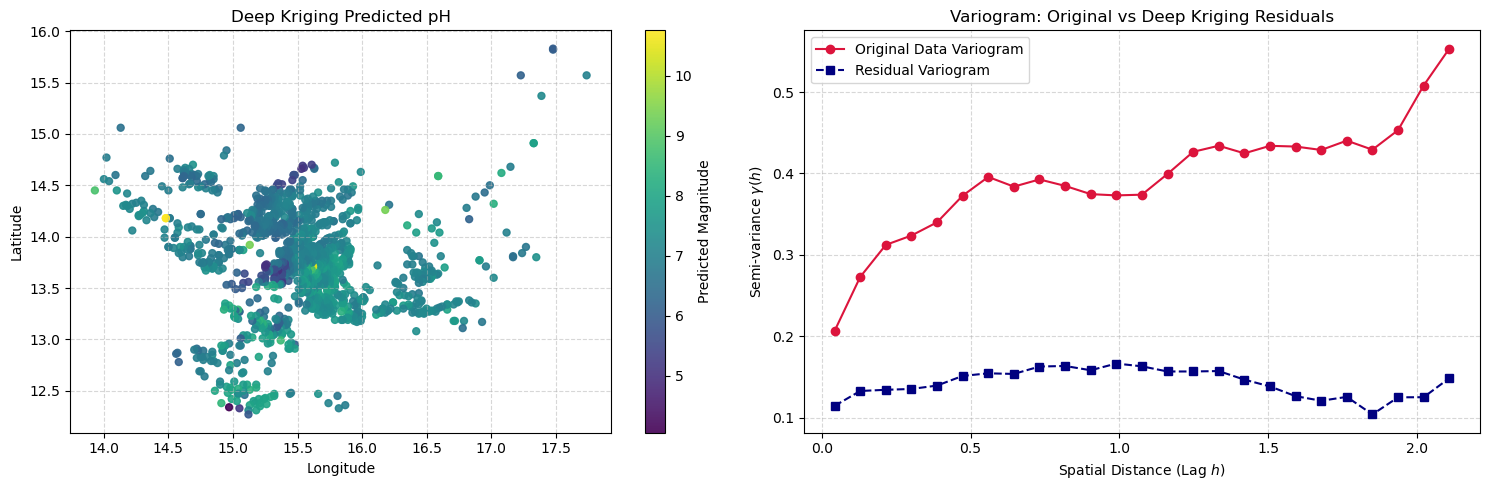

In [61]:
############## 7. Residual Variogram and Spatial Interpolation Plots
# Computing the fitted values for entire dataset
model.eval()
with torch.no_grad():
    all_preds = model(torch.tensor(X_scaled, dtype = torch.float32)).numpy().flatten()

residuals = target - all_preds

# Computing the variogram of residuals
lags_res, gamma_res = compute_empirical_variogram(coords, residuals, n_lags = 25)

# Plotting the Spatial Map and Variogram Comparison
fig, axes = plt.subplots(1, 2, figsize = (15, 5))

# 1. Spatial Interpolation Contour / Scatter
sc = axes[0].scatter(data['x_coord'], data['y_coord'], c = all_preds, cmap = 'viridis', s = 25, alpha = 0.9)
fig.colorbar(sc, ax=axes[0], label='Predicted Magnitude')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_title('Deep Kriging Predicted pH')
axes[0].grid(True, linestyle = '--', alpha = 0.5)

# 2. Variogram Comparison (Original vs Residuals)
axes[1].plot(lags, gamma, 'o-', color = 'crimson', label = 'Original Data Variogram')
axes[1].plot(lags_res, gamma_res, 's--', color='navy', label = 'Residual Variogram')
axes[1].set_xlabel('Spatial Distance (Lag $h$)')
axes[1].set_ylabel('Semi-variance $\gamma(h)$')
axes[1].set_title('Variogram: Original vs Deep Kriging Residuals')
axes[1].grid(True, linestyle = '--', alpha = 0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

In [30]:
########## To add spatial uncertainty estimation (e.g., Monte Carlo Dropout) to mimic Ordinary Kriging variance
#i.e. how to extend the Deep Kriging model with Monte Carlo (MC) Dropout to quantify spatial uncertainty and generate kriging variance maps.

In [62]:
# a, Creating a Deep Kriging Neural Network class with Dropout for Monte Carlo Uncertainty
class DeepKrigingUncertaintyModel(nn.Module):
    """
    Deep Kriging Neural Network with Dropout for Monte Carlo Uncertainty Estimation
    """
    def __init__(self, embedding_dim = 256, hidden_units = [128, 64, 32], dropout_rate= 0.29):
        super().__init__()
        self.rff = RandomFourierEmbedding(in_features = 2, num_features=embedding_dim, sigma = 0.5)
        
        layers = []
        prev_dim = embedding_dim
        for h in hidden_units:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(p=dropout_rate))
            prev_dim = h
            
        layers.append(nn.Linear(prev_dim, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        embedded = self.rff(x)
        return self.network(embedded)


In [63]:
# b. Initializing the model
mc_model = DeepKrigingUncertaintyModel(embedding_dim = 256, dropout_rate = 0.29)
criterion = nn.MSELoss()
optimizer = optim.RMSprop(mc_model.parameters(), lr = 0.003, weight_decay = 1e-4)


In [64]:
#  c.Training the model
epochs = 350
for epoch in range(epochs):
    mc_model.train()
    optimizer.zero_grad()
    preds = mc_model(X_train_t)
    loss = criterion(preds, y_train_t)
    loss.backward()
    optimizer.step()

print(f"Training Complete. Final Train Loss: {loss.item():.2f}")


Training Complete. Final Train Loss: 2.17


In [34]:
########## 2. The Monte Carlo Inference Function

In [65]:
## a. Performing Monte Carlo Sampling
def predict_mc_dropout(model, X_tensor, num_samples = 100):
    """
    Performs Monte Carlo Sampling to compute mean predictions and spatial variance.
    """
    model.train()  # Keep dropout active during inference
    predictions = []
    
    with torch.no_grad():
        for _ in range(num_samples):
            pred = model(X_tensor).numpy().flatten()
            predictions.append(pred)
            
    predictions = np.array(predictions)  # Shape: (num_samples, num_points)
    
    mean_pred = np.mean(predictions, axis = 0)
    variance_pred = np.var(predictions, axis = 0)
    
    return mean_pred, variance_pred

In [67]:
# c. Running the MC Sampling across the dataset
X_all_t = torch.tensor(X_scaled, dtype = torch.float32)
mean_preds, spatial_variances = predict_mc_dropout(mc_model, X_all_t, num_samples = 100)

In [68]:
############## 3. Dense Grid Interpolation and Kriging Variance Maps

In [69]:
# a. Creating a dense grid covering the geographic bounding box
grid_lat = np.linspace(data['y_coord'].min() - 0.5, data['y_coord'].max() + 0.5, 100)
grid_long = np.linspace(data['x_coord'].min() - 0.5, data['x_coord'].max() + 0.5, 100)
grid_lon_mesh, grid_lat_mesh = np.meshgrid(grid_long, grid_lat)

grid_coords = np.column_stack([grid_lat_mesh.ravel(), grid_lon_mesh.ravel()])
grid_coords_scaled = scaler_coords.transform(grid_coords)
grid_tensor = torch.tensor(grid_coords_scaled, dtype = torch.float32)

In [70]:
# b. Estimating mean and variance over the entire grid
grid_means, grid_variances = predict_mc_dropout(mc_model, grid_tensor, num_samples = 100)

grid_means_surface = grid_means.reshape(grid_lat_mesh.shape)
grid_variance_surface = grid_variances.reshape(grid_lat_mesh.shape)

<>:16: SyntaxWarning: invalid escape sequence '\s'
<>:16: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Djimadoumngar\AppData\Local\Temp\ipykernel_14320\2225314319.py:16: SyntaxWarning: invalid escape sequence '\s'
  fig.colorbar(cs2, ax = axes[1], label = 'Kriging Variance ($\sigma^2$)')


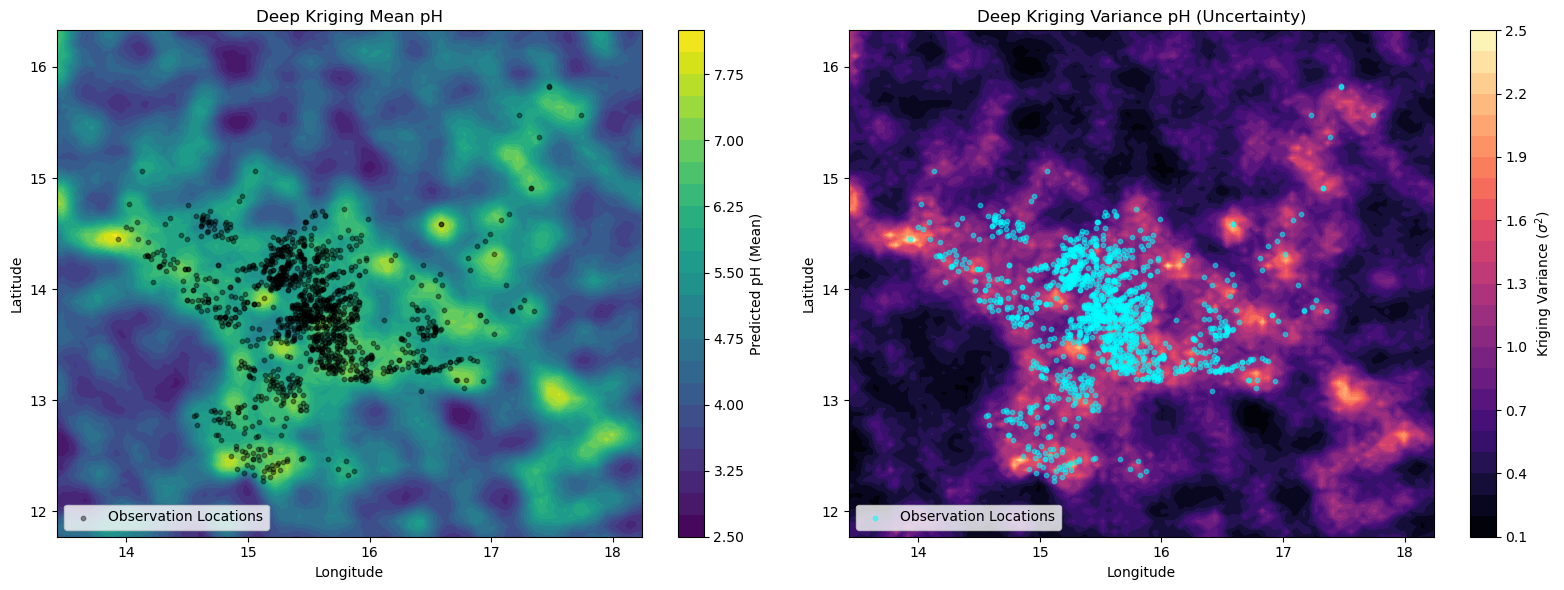

In [71]:
# c. Plotting the Mean Surface vs. Deep Kriging Variance
fig, axes = plt.subplots(1, 2, figsize = (16, 6))

# 1. Spatial Mean Surface
cs1 = axes[0].contourf(grid_lon_mesh, grid_lat_mesh, grid_means_surface, levels = 25, cmap = 'viridis')
axes[0].scatter(data['x_coord'], data['y_coord'], c='k', s = 10, alpha = 0.4, label = 'Observation Locations')
fig.colorbar(cs1, ax = axes[0], label = 'Predicted pH (Mean)')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_title('Deep Kriging Mean pH')
axes[0].legend(loc='lower left')

# 2. Spatial Uncertainty (Variance) Surface
cs2 = axes[1].contourf(grid_lon_mesh, grid_lat_mesh, grid_variance_surface, levels=25, cmap = 'magma')
axes[1].scatter(data['x_coord'], data['y_coord'], c = 'cyan', s = 10, alpha = 0.5, label = 'Observation Locations')
fig.colorbar(cs2, ax = axes[1], label = 'Kriging Variance ($\sigma^2$)')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].set_title('Deep Kriging Variance pH (Uncertainty)')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()